In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

serie = torch.sin(torch.linspace(0, 20, 200))
X = torch.stack([serie[i:i + 10] for i in range(190)]).unsqueeze(-1)  # (190, 10, 1)
y = torch.stack([serie[i + 10] for i in range(190)]).unsqueeze(-1)    # (190, 1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

In [2]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, (h, c) = self.lstm(x)    # h : état caché, c : mémoire de cellule
        dernier = etats[:, -1, :]       # (B, 16)
        return self.sortie(dernier)     # (B, 1)

modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [3]:
for epoch in range(300):
    modele.train()
    perte = critere(modele(X_train), y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1} | perte : {perte.item():.6f}")

modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    print(f"\nErreur de test (MSE) : {critere(predictions, y_test).item():.6f}")

Epoch 50 | perte : 0.003562
Epoch 100 | perte : 0.000248
Epoch 150 | perte : 0.000043
Epoch 200 | perte : 0.000006
Epoch 250 | perte : 0.000004
Epoch 300 | perte : 0.000003

Erreur de test (MSE) : 0.000003


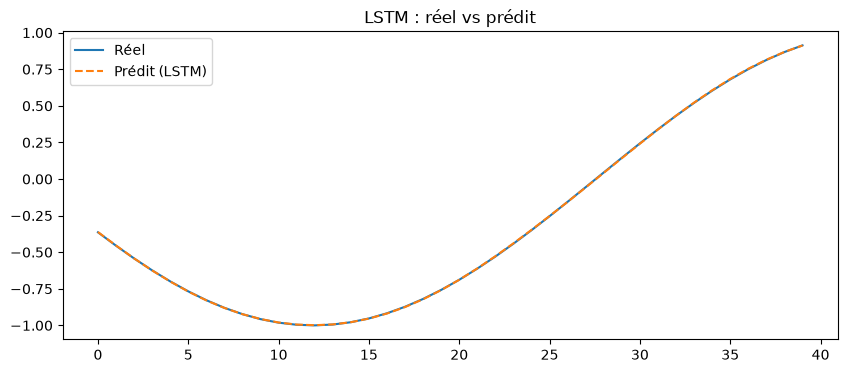

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(y_test.numpy(), label="Réel")
plt.plot(predictions.numpy(), "--", label="Prédit (LSTM)")
plt.title("LSTM : réel vs prédit")
plt.legend()
plt.show()